In [1]:
from dotenv import load_dotenv
import os
from pathlib import Path

from dbs import bucket_exists, ensure_bucket, list_objects, upload_file, read_file
from dbs.graph import get_graph_db, ArangoBackend, MemgraphBackend


load_dotenv()

True

Bucket 'tfm' exists.
Found objects: ['first_upload', 'researchers.csv', 'researchers/258423/activity.html', 'researchers/258423/profile.html', '...']
Content of 'first_upload':    <!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8" />
    <title>CARLOS BADENES OLMEDO - Universidad Politécnica de Madrid</title>
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <meta name="author" content="iMarina">
    <meta http-equiv="X-UA-Compatible" content="IE=edge" />
    <meta name="Description" lang="es" content="Carlos Badenes-Olmedo es profesor asociado en la Universidad Politécnica de Madrid (UPM), investigador en el Grupo de Ingeniería Ontológica (OEG), y co-fundador de librairy.eu, una spin-off con base tecnológica que facilita la exploración de grandes corpus documentales. Combina la docencia en Aprendizaje Automático, Procesamiento de Lenguaje Natural y Codificación en Python, con la investigación de técnicas avanzadas para extracción de conocimi
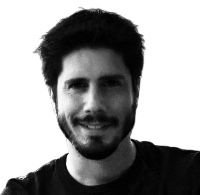

In [2]:
BUCKET_NAME = os.environ.get("MINIO_BUCKET_NAME")
local_file_path = Path("./data/carlos_badenes_olmedo.json")

if bucket_exists(BUCKET_NAME):
    print(f"Bucket '{BUCKET_NAME}' exists.")
    my_objects = list_objects(bucket_name=BUCKET_NAME, prefix="", recursive=True)
    print(
        f"Found objects: {my_objects if len(my_objects) <= 4 else my_objects[:4] + ['...']}"
    )
else:
    ensure_bucket(BUCKET_NAME, must_exist=False)
    print(f"Bucket '{BUCKET_NAME}' created.")
    upload_file(BUCKET_NAME, local_file_path, object_name="first_upload")

file_content = read_file(BUCKET_NAME, "first_upload")
print(f"Content of 'first_upload': {file_content}")

---

## Graph Databases

In [3]:
pdis = [
    {
        "id": "pdi_412985",
        "email": "elena.gomez@upm.es",
        "external_ids": {
            "dialnet_id": "7654321",
            "google_scholar_id": "A8B9C1D&hl=es",
            "linkedin_id": "elena-gomez-pastrana",
            "mendeley_id": None,
            "orcid_id": "0000-0003-1415-9265",
            "personal_web": None,
            "researcher_id": "GRE-5541-2023",
            "researchgate_id": "Elena-Gomez-Pastrana",
            "scopus_id": "57210984321",
        },
        "first_name": "Elena",
        "full_name": "GÓMEZ PASTRANA, ELENA",
        "last_name": "Gómez Pastrana",
        "positions": {
            "Departamento Universitario": {
                "id": "loc_17101",
                "entity": "FÍSICA APLICADA",
                "role": "Catedrática de Universidad",
                "since": "2018-05-14",
            },
            "Grupo de investigacion": {
                "id": "loc_16312",
                "entity": "Sistemas Cuánticos y Fotónica",
                "role": "Directora",
                "since": "2019-11-01",
            },
            "Instituto o centro Universitario de Investigación": {
                "id": "loc_16045",
                "entity": "Instituto de Optoelectrónica y Microtecnología",
                "role": "Investigadora Principal",
                "since": "2021-02-18",
            },
        },
        "topics": [
            "quantum computing",
            "photonics",
            "semiconductors",
            "laser diodes",
            "optics",
            "nanotechnology",
            "quantum cryptography",
            "solid-state physics",
            "thin films",
            "numerical simulation",
            "spectroscopy",
            "waveguides",
            "fiber optics",
            "optoelectronics",
        ],
    },
    {
        "id": "pdi_105432",
        "email": "alejandro.ruiz@upm.es",
        "external_ids": {
            "dialnet_id": None,
            "google_scholar_id": None,
            "linkedin_id": "alejandro-ruiz-ortiz",
            "mendeley_id": "alejandro-ruiz-ortiz",
            "orcid_id": "0000-0001-9876-5432",
            "personal_web": "https://alejandroruiz.github.io",
            "researcher_id": None,
            "researchgate_id": "Alejandro-Ruiz-Ortiz",
            "scopus_id": "55987654321",
        },
        "first_name": "Alejandro",
        "full_name": "RUIZ ORTIZ, ALEJANDRO",
        "last_name": "Ruiz Ortiz",
        "positions": {
            "Departamento Universitario": {
                "id": "loc_15234",
                "entity": "ORGANIZACIÓN DE EMPRESAS",
                "role": "Profesor Titular",
                "since": "2020-09-15",
            },
            "Grupo de investigacion": {
                "id": "loc_16111",
                "entity": "Gestión de la Innovación y Sostenibilidad",
                "role": "Miembro",
                "since": "2021-01-10",
            },
            "Instituto o centro Universitario de Investigación": {
                "id": "loc_16999",
                "entity": "Centro de Apoyo a la Innovación Tecnológica (CAIT)",
                "role": "Colaborador",
                "since": "2023-06-01",
            },
        },
        "topics": [
            "supply chain management",
            "circular economy",
            "business models",
            "innovation strategy",
            "operations research",
            "industry 4.0",
            "sustainability indicators",
            "logistics network design",
            "project management",
            "decision-making models",
            "linear programming",
            "risk analysis",
            "technology transfer",
            "corporate social responsibility",
            "life cycle assessment",
        ],
    },
]

publications = [
    {
        "id": "pub_9910001",
        "authors": "E Gómez-Pastrana, A Ruiz-Ortiz, M Santos,",
        "end_date": None,
        "keywords": None,
        "oa_id": None,
        "portal_upm_id": "9910001",
        "start_date": None,
        "name": "Optimizing Supply Chain Logistics through Quantum Computing and Industry 4.0",
        "type": "Artículo",
        "url": "https://portalcientifico.upm.es/es/ipublic/item/9910001",
        "year": None,
    },
    {
        "id": "pub_9910002",
        "authors": "E Gómez-Pastrana, L Ferrero,",
        "end_date": None,
        "keywords": None,
        "oa_id": None,
        "portal_upm_id": "9910002",
        "start_date": None,
        "name": "Advances in Semiconductor Laser Diodes for Quantum Cryptography",
        "type": "Artículo",
        "url": "https://portalcientifico.upm.es/es/ipublic/item/9910002",
        "year": None,
    },
    {
        "id": "pub_9910003",
        "authors": "J M Moreno, E Gómez-Pastrana,",
        "end_date": None,
        "keywords": None,
        "oa_id": None,
        "portal_upm_id": "9910003",
        "start_date": None,
        "name": "Numerical Simulation of Waveguides in Nanotechnology Applications",
        "type": "Artículo",
        "url": "https://portalcientifico.upm.es/es/ipublic/item/9910003",
        "year": None,
    },
    {
        "id": "pub_9910004",
        "authors": "A Ruiz-Ortiz, P Jimenez,",
        "end_date": None,
        "keywords": None,
        "oa_id": None,
        "portal_upm_id": "9910004",
        "start_date": None,
        "name": "Circular Economy Indicators for Sustainability Assessment in Manufacturing",
        "type": "Artículo",
        "url": "https://portalcientifico.upm.es/es/ipublic/item/9910004",
        "year": None,
    },
    {
        "id": "pub_9910005",
        "authors": "A Ruiz-Ortiz, T Alarcón, R Gil,",
        "end_date": None,
        "keywords": None,
        "oa_id": None,
        "portal_upm_id": "9910005",
        "start_date": None,
        "name": "Linear Programming Models for Risk Analysis in Project Management",
        "type": "Artículo",
        "url": "https://portalcientifico.upm.es/es/ipublic/item/9910005",
        "year": None,
    },
]

relations = [
    {
        "_from": "pdi/pdi_412985",
        "id": "authorship_pdi_412985_pub_9910001",
        "_to": "publications/pub_9910001",
    },
    {
        "_from": "pdi/pdi_412985",
        "id": "authorship_pdi_412985_pub_9910002",
        "_to": "publications/pub_9910002",
    },
    {
        "_from": "pdi/pdi_412985",
        "id": "authorship_pdi_412985_pub_9910003",
        "_to": "publications/pub_9910003",
    },
    {
        "_from": "pdi/pdi_105432",
        "id": "authorship_pdi_105432_pub_9910001",
        "_to": "publications/pub_9910001",
    },
    {
        "_from": "pdi/pdi_105432",
        "id": "authorship_pdi_105432_pub_9910004",
        "_to": "publications/pub_9910004",
    },
    {
        "_from": "pdi/pdi_105432",
        "id": "authorship_pdi_105432_pub_9910005",
        "_to": "publications/pub_9910005",
    },
]

### ArangoDB

In [4]:
ARANGO_DB_NAME = "test"
arango: ArangoBackend = get_graph_db("arango", db_name=ARANGO_DB_NAME)
arango.ensure_collections()

KeyboardInterrupt: 

In [ ]:
for col in ["pdi", "publications", "authorship"]:
    arango.clear_collection(col)

pdis_uploades = arango.upsert_documents(collection="pdi", docs=pdis)
publications_uploaded = arango.upsert_documents(
    collection="publications", docs=publications
)
relations_uploaded = arango.upsert_edges(collection="authorship", edges=relations)

print(f"Uploaded PDI documents: {pdis_uploades}")
print(f"Uploaded publications: {publications_uploaded}")
print(f"Uploaded relations: {relations_uploaded}")

print(
    arango.query("FOR p IN pdi RETURN {id: p._key, name: p.full_name, email: p.email}")
)
print(arango.query("FOR p IN publications RETURN {id: p._key, title: p.title}"))

Uploaded PDI documents: 2
Uploaded publications: 5
Uploaded relations: 6
[{'id': 'pdi_412985', 'name': 'GÓMEZ PASTRANA, ELENA', 'email': 'elena.gomez@upm.es'}, {'id': 'pdi_105432', 'name': 'RUIZ ORTIZ, ALEJANDRO', 'email': 'alejandro.ruiz@upm.es'}]
[{'id': 'pub_9910001', 'title': 'Optimizing Supply Chain Logistics through Quantum Computing and Industry 4.0'}, {'id': 'pub_9910002', 'title': 'Advances in Semiconductor Laser Diodes for Quantum Cryptography'}, {'id': 'pub_9910003', 'title': 'Numerical Simulation of Waveguides in Nanotechnology Applications'}, {'id': 'pub_9910004', 'title': 'Circular Economy Indicators for Sustainability Assessment in Manufacturing'}, {'id': 'pub_9910005', 'title': 'Linear Programming Models for Risk Analysis in Project Management'}]


### Memgraph

In [2]:
memgraph: MemgraphBackend = get_graph_db("memgraph")
memgraph.ensure_collections()

2026-05-30 12:18:41.580 | DEBUG    | dbs.graph.memgraph:__init__:41 - Connected to Memgraph at localhost:7687
2026-05-30 12:18:43.993 | DEBUG    | dbs.graph.memgraph:ensure_collections:53 - Memgraph connection verified and ready for collections


In [6]:
for col in ["Pdi", "Publication", "Authorship"]:
    memgraph.clear_collection(col)

pdis_to_upload = [
    {
        "id": pdi["id"],
        "email": pdi["email"],
        "first_name": pdi["first_name"],
        "full_name": pdi["full_name"],
        "last_name": pdi["last_name"],
        **pdi["external_ids"],
    }
    for pdi in pdis
]

pdis_uploaded = memgraph.upsert_documents(collection="Pdi", docs=pdis_to_upload)
publications_uploaded = memgraph.upsert_documents(
    collection="Publication", docs=publications
)
relations_uploaded = memgraph.upsert_edges(collection="Authorship", edges=relations)

print(f"Uploaded PDI documents: {pdis_uploaded}")
print(f"Uploaded publications: {publications_uploaded}")
print(f"Uploaded relations: {relations_uploaded}")

print(
    memgraph.query(
        "MATCH (p:Pdi) RETURN p.id AS id, p.full_name AS name, p.email AS email"
    )
)
print(memgraph.query("MATCH (p:Publication) RETURN p.id AS id, p.name AS title"))

2026-05-22 17:48:59.763 | DEBUG    | dbs.graph.memgraph:clear_collection:288 - Cleared collection Pdi
2026-05-22 17:48:59.806 | DEBUG    | dbs.graph.memgraph:clear_collection:288 - Cleared collection Publication
2026-05-22 17:48:59.813 | DEBUG    | dbs.graph.memgraph:clear_collection:288 - Cleared collection Authorship
2026-05-22 17:48:59.837 | DEBUG    | dbs.graph.memgraph:upsert_documents:177 - Upserted 2 documents into Pdi
2026-05-22 17:48:59.867 | DEBUG    | dbs.graph.memgraph:upsert_documents:177 - Upserted 5 documents into Publication
2026-05-22 17:48:59.898 | DEBUG    | dbs.graph.memgraph:upsert_edges:240 - Upserted 6 edges of type Authorship


Uploaded PDI documents: 2
Uploaded publications: 5
Uploaded relations: 6
[{'id': 'pdi_412985', 'name': 'GÓMEZ PASTRANA, ELENA', 'email': 'elena.gomez@upm.es'}, {'id': 'pdi_105432', 'name': 'RUIZ ORTIZ, ALEJANDRO', 'email': 'alejandro.ruiz@upm.es'}]
[{'id': 'pub_9910001', 'title': 'Optimizing Supply Chain Logistics through Quantum Computing and Industry 4.0'}, {'id': 'pub_9910002', 'title': 'Advances in Semiconductor Laser Diodes for Quantum Cryptography'}, {'id': 'pub_9910003', 'title': 'Numerical Simulation of Waveguides in Nanotechnology Applications'}, {'id': 'pub_9910004', 'title': 'Circular Economy Indicators for Sustainability Assessment in Manufacturing'}, {'id': 'pub_9910005', 'title': 'Linear Programming Models for Risk Analysis in Project Management'}]


In [7]:
# Query for relationship table
q1 = """
MATCH (pdi: Pdi)
WITH pdi LIMIT 10
MATCH (pdi)-[:Authorship]->(pub:Publication)
RETURN pdi.email AS email, collect(pub.name) AS publicacions
"""
memgraph.query(q1)

[]

In [8]:
# Query for relationship graph
q2 = """
MATCH (pdi: Pdi)
WITH pdi LIMIT 10
MATCH (pdi)-[auth:Authorship]->(pub:Publication)
RETURN pdi, auth, pub
"""
memgraph.query(q2)

[]

In [9]:
# Query for graph algorithms (PageRank)
q3 = """
CALL pagerank.get() YIELD node, rank
RETURN node, rank
ORDER BY rank DESC
LIMIT 10
"""
memgraph.query(q3)

c:\Users\Yago\Desktop\MAADM\X TFM\UPM_Match\.venv\Lib\site-packages\gqlalchemy\models.py:398: GQLAlchemySubclassNotFoundWarning: ({'Subject'}, <class 'gqlalchemy.models.Node'>)
  warnings.warn(GQLAlchemySubclassNotFoundWarning(types, cls))


[{'node': <Node id=50093 labels={'Subject'} properties={'id': 'subj_863dfbf8', 'type': 'Docencia Oficial Nacional', 'name': 'Proyecto De Estructuras'}>,
  'rank': 0.00022696323195641374},
 {'node': <Node id=50092 labels={'Subject'} properties={'id': 'subj_b978b808', 'type': 'Docencia Oficial Nacional', 'name': 'Proyecto De Calculo Integrado De La Estructura De Un Edificio'}>,
  'rank': 0.00022696323195641374},
 {'node': <Node id=50091 labels={'Subject'} properties={'id': 'subj_cf211434', 'type': 'Docencia Oficial Nacional', 'name': 'Programas De Analisis Estructural'}>,
  'rank': 0.00022696323195641374},
 {'node': <Node id=50090 labels={'Subject'} properties={'id': 'subj_87de1e3b', 'type': 'Docencia Oficial Nacional', 'name': 'Modelos Estructurales: Base De La Normativa'}>,
  'rank': 0.00022696323195641374},
 {'node': <Node id=50089 labels={'Subject'} properties={'id': 'subj_93d7baca', 'type': 'Docencia Oficial Nacional', 'name': 'La Estructura En El Proyecto Arquitectonico'}>,
  'rank

In [4]:
memgraph.clear_database()

2026-05-29 22:22:29.222 | INFO     | dbs.graph.memgraph:clear_database:306 - Cleared all nodes and relationships from Memgraph database


True